In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Indian Air Quality Analysis")
print("Libraries imported successfully!")

Indian Air Quality Analysis
Libraries imported successfully!


In [2]:
import requests

url = "https://api.openaq.org/v3/locations"

response = requests.get(
    url,
    params={
        "country_id": "IN",
        "limit": 5
    },
    timeout=30
)

print("Status code:", response.status_code)

if response.status_code == 200:
    data = response.json()
    print("API connection successful!")
    print("Number of locations returned:", len(data.get("results", [])))

    for location in data.get("results", []):
        print(
            "Location:", location.get("name"),
            "| ID:", location.get("id")
        )
else:
    print("Request failed:", response.text[:500])

Status code: 401
Request failed: {"message": "Unauthorized. A valid API key must be provided in the X-API-Key header."}


In [3]:
from getpass import getpass

AQI_API_KEY = getpass("Enter your India Air Quality API key: ")

print("API key received.")

Enter your India Air Quality API key: ··········
API key received.


In [4]:
import requests

url = "https://airquality.xkdr.org/v1/meta"

response = requests.get(
    url,
    headers={"Authorization": f"Bearer {AQI_API_KEY}"},
    timeout=30
)

print("Status code:", response.status_code)

if response.status_code == 200:
    print("Connection successful!")
    meta = response.json()
    print(meta)
else:
    print("Request failed. Check the status code and error message.")

Status code: 200
Connection successful!
{'schema_version': 'v1', 'exported_at': '2026-09-30T11:25:11+00:00', 'timezone_note': 'collected_at is a naive timestamp in Indian Standard Time (UTC+05:30).', 'columns': {'station_id': 'VARCHAR', 'station_name': 'VARCHAR', 'state_name': 'VARCHAR', 'city_name': 'VARCHAR', 'parameter_name': 'VARCHAR', 'unit': 'VARCHAR', 'collected_at': 'TIMESTAMP', 'value': 'DOUBLE', 'source': "VARCHAR ('cpcb_caaqm' | 'us_embassy')", 'year': 'hive partition', 'month': 'hive partition'}, 'measurements': {'rows': 196521834, 'bytes': 409568028, 'n_months': 207, 'first_month': '2009-01', 'last_month': '2026-03'}, 'stations': 558, 'parameters': 15, 'your_tier': 'full', 'max_rows_per_query': None, 'query_timeout_seconds': 90.0}


In [5]:
import requests
import pandas as pd

url = "https://airquality.xkdr.org/v1/stations"

response = requests.get(
    url,
    headers={"Authorization": f"Bearer {AQI_API_KEY}"},
    params={"city": "Delhi"},
    timeout=30
)

print("Status code:", response.status_code)

if response.status_code == 200:
    stations_data = response.json()
    stations = pd.DataFrame(stations_data.get("results", []))

    print("Stations returned:", len(stations))
    display(stations.head(10))
else:
    print(response.text[:500])

Status code: 200
Stations returned: 0


""


In [6]:
import requests
import pandas as pd

url = "https://airquality.xkdr.org/v1/stations"

response = requests.get(
    url,
    headers={"Authorization": f"Bearer {AQI_API_KEY}"},
    params={"q": "Delhi"},
    timeout=30
)

print("Status code:", response.status_code)

if response.status_code == 200:
    result = response.json()
    print("Response keys:", result.keys())

    stations = pd.DataFrame(result.get("results", []))
    print("Stations returned:", len(stations))
    display(stations.head(10))
else:
    print(response.text[:500])

Status code: 200
Response keys: dict_keys(['meta', 'data'])
Stations returned: 0


""


In [7]:
print("Response metadata:")
print(result.get("meta"))

print("\nData type:")
print(type(result.get("data")))

print("\nFirst part of data:")
print(str(result.get("data"))[:2000])

Response metadata:
{'filters': {'source': None, 'state': None, 'city': None, 'q': 'Delhi'}, 'rows': 40, 'truncated': False, 'max_rows': 100000, 'query_ms': 201}

Data type:
<class 'list'>

First part of data:
[{'station_id': 'site_5024', 'station_name': 'Alipur, Delhi - DPCC', 'state_name': 'Delhi', 'city_name': 'Delhi', 'source': 'cpcb_caaqm', 'latitude': 28.815329, 'longitude': 77.15301, 'first_seen': '2018-11-11T14:00:00', 'last_seen': '2025-09-01T17:00:00', 'n_rows': 618096, 'parameters': ['Benzene', 'CO', 'Eth-Benzene', 'MP-Xylene', 'NH3', 'NO', 'NO2', 'NOx', 'Ozone', 'PM10', 'PM2.5', 'SO2', 'Toluene', 'Xylene']}, {'station_id': 'site_301', 'station_name': 'Anand Vihar, Delhi - DPCC', 'state_name': 'Delhi', 'city_name': 'Delhi', 'source': 'cpcb_caaqm', 'latitude': 28.647622, 'longitude': 77.315809, 'first_seen': '2012-09-01T00:00:00', 'last_seen': '2025-09-01T23:00:00', 'n_rows': 797517, 'parameters': ['Benzene', 'CO', 'NH3', 'NO', 'NO2', 'NOx', 'Ozone', 'PM10', 'PM2.5', 'SO2', 'T

In [8]:
import requests
import pandas as pd
from io import StringIO

url = "https://airquality.xkdr.org/v1/measurements"

response = requests.get(
    url,
    headers={"Authorization": f"Bearer {AQI_API_KEY}"},
    params={
        "station": "site_301",
        "parameter": "PM2.5",
        "start": "2024-11-01",
        "end": "2024-11-30",
        "agg": "daily",
        "format": "csv"
    },
    timeout=60
)

print("Status code:", response.status_code)

if response.status_code == 200:
    pm25_df = pd.read_csv(StringIO(response.text))
    print("Rows downloaded:", len(pm25_df))
    print("Columns:", pm25_df.columns.tolist())
    display(pm25_df.head())
else:
    print(response.text[:500])

Status code: 200
Rows downloaded: 30
Columns: ['station_id', 'parameter_name', 'unit', 'period_start', 'mean', 'min', 'max', 'n']


,station_id,parameter_name,unit,period_start,mean,min,max,n
0,site_301,PM2.5,µg/m³,2024-11-01 00:00:00,295.456522,53.0,992.0,23
1,site_301,PM2.5,µg/m³,2024-11-02 00:00:00,312.416667,135.0,840.0,24
2,site_301,PM2.5,µg/m³,2024-11-03 00:00:00,316.916667,106.0,549.0,24
3,site_301,PM2.5,µg/m³,2024-11-04 00:00:00,338.541667,172.0,611.0,24
4,site_301,PM2.5,µg/m³,2024-11-05 00:00:00,274.300000,107.0,427.0,20


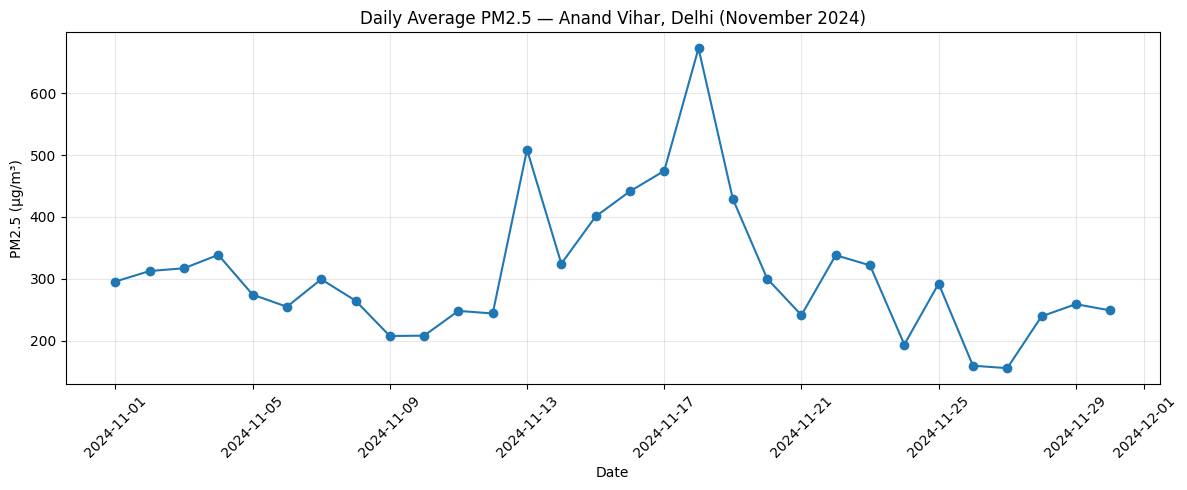

Monthly average: 308.72 µg/m³
Highest daily average: 672.58 µg/m³
Lowest daily average: 155.31 µg/m³


In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert dates to datetime
pm25_df["period_start"] = pd.to_datetime(pm25_df["period_start"])

# Sort data by date
pm25_df = pm25_df.sort_values("period_start")

# Plot daily average PM2.5
plt.figure(figsize=(12, 5))
plt.plot(
    pm25_df["period_start"],
    pm25_df["mean"],
    marker="o"
)

plt.title("Daily Average PM2.5 — Anand Vihar, Delhi (November 2024)")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Monthly average:", round(pm25_df["mean"].mean(), 2), "µg/m³")
print("Highest daily average:", round(pm25_df["mean"].max(), 2), "µg/m³")
print("Lowest daily average:", round(pm25_df["mean"].min(), 2), "µg/m³")

In [10]:
print("Total records:", len(pm25_df))
print("Missing daily averages:", pm25_df["mean"].isna().sum())
print("Duplicate dates:", pm25_df["period_start"].duplicated().sum())

print("\nDate range:")
print(pm25_df["period_start"].min())
print("to", pm25_df["period_start"].max())

print("\nSummary statistics:")
display(pm25_df["mean"].describe())

Total records: 30
Missing daily averages: 0
Duplicate dates: 0

Date range:
2024-11-01 00:00:00
to 2024-11-30 00:00:00

Summary statistics:


,mean
count,30.000000
mean,308.722819
std,110.203747
min,155.312500
25%,244.812500
50%,293.796443
75%,334.596467
max,672.583333


In [11]:
# Show the Delhi stations available in the API response
stations_df = pd.DataFrame(result["data"])

print("Total Delhi stations:", len(stations_df))

display(
    stations_df[
        ["station_id", "station_name", "city_name", "parameters"]
    ].head(10)
)

Total Delhi stations: 40


,station_id,station_name,city_name,parameters
0,site_5024,"Alipur, Delhi - DPCC",Delhi,"[Benzene, CO, Eth-Benzene, MP-Xylene, NH3, NO,..."
1,site_301,"Anand Vihar, Delhi - DPCC",Delhi,"[Benzene, CO, NH3, NO, NO2, NOx, Ozone, PM10, ..."
2,site_1420,"Ashok Vihar, Delhi - DPCC",Delhi,"[Benzene, CO, NH3, NO, NO2, NOx, Ozone, PM10, ..."
3,site_108,"Aya Nagar, Delhi - IMD",Delhi,"[Benzene, CO, Eth-Benzene, NO, NO2, NOx, Ozone..."
4,site_1560,"Bawana, Delhi - DPCC",Delhi,"[Benzene, CO, NH3, NO, NO2, NOx, Ozone, PM10, ..."
5,site_104,"Burari Crossing, Delhi - IMD",Delhi,"[Benzene, CO, NO, NO2, NOx, Ozone, PM10, PM2.5]"
6,site_103,"CRRI Mathura Road, Delhi - IMD",Delhi,"[Benzene, CO, Eth-Benzene, NO, NO2, NOx, Ozone..."
7,site_5393,"Chandni Chowk, Delhi - IITM",Delhi,"[Benzene, CO, Eth-Benzene, MP-Xylene, NH3, NO,..."
8,site_118,"DTU, Delhi - CPCB",Delhi,"[Benzene, CO, Eth-Benzene, MP-Xylene, NH3, NO,..."
9,site_1421,"Dr. Karni Singh Shooting Range, Delhi - DPCC",Delhi,"[Benzene, CO, NH3, NO, NO2, NOx, Ozone, PM10, ..."


In [12]:
# Filter Delhi stations that report PM2.5
pm25_stations = stations_df[
    stations_df["parameters"].apply(
        lambda params: isinstance(params, list)
        and any(p.upper() == "PM2.5" for p in params)
    )
].copy()

print("Stations reporting PM2.5:", len(pm25_stations))

display(
    pm25_stations[
        ["station_id", "station_name", "first_seen", "last_seen"]
    ].head(15)
)

Stations reporting PM2.5: 40


,station_id,station_name,first_seen,last_seen
0,site_5024,"Alipur, Delhi - DPCC",2018-11-11T14:00:00,2025-09-01T17:00:00
1,site_301,"Anand Vihar, Delhi - DPCC",2012-09-01T00:00:00,2025-09-01T23:00:00
2,site_1420,"Ashok Vihar, Delhi - DPCC",2018-02-01T08:00:00,2025-09-01T21:00:00
3,site_108,"Aya Nagar, Delhi - IMD",2017-09-06T14:00:00,2025-09-01T23:00:00
4,site_1560,"Bawana, Delhi - DPCC",2018-07-04T18:00:00,2025-09-01T19:00:00
5,site_104,"Burari Crossing, Delhi - IMD",2017-01-01T00:00:00,2025-09-01T19:00:00
6,site_103,"CRRI Mathura Road, Delhi - IMD",2017-01-01T00:00:00,2025-09-01T23:00:00
7,site_5393,"Chandni Chowk, Delhi - IITM",2020-11-13T14:00:00,2025-09-01T23:00:00
8,site_118,"DTU, Delhi - CPCB",2009-01-01T00:00:00,2025-09-01T23:00:00
9,site_1421,"Dr. Karni Singh Shooting Range, Delhi - DPCC",2018-02-01T08:00:00,2025-09-01T23:00:00


In [13]:
import requests
import pandas as pd
from io import StringIO
import time

selected_stations = pm25_stations.head(5)

all_station_data = []

for _, station in selected_stations.iterrows():
    response = requests.get(
        "https://airquality.xkdr.org/v1/measurements",
        headers={"Authorization": f"Bearer {AQI_API_KEY}"},
        params={
            "station": station["station_id"],
            "parameter": "PM2.5",
            "start": "2024-11-01",
            "end": "2024-11-30",
            "agg": "daily",
            "format": "csv"
        },
        timeout=60
    )

    if response.status_code == 200 and response.text.strip():
        station_df = pd.read_csv(StringIO(response.text))
        station_df["station_name"] = station["station_name"]
        all_station_data.append(station_df)
        print(station["station_name"], "—", len(station_df), "rows")
    else:
        print(station["station_name"], "— request failed:", response.status_code)

    time.sleep(0.3)

if all_station_data:
    comparison_df = pd.concat(all_station_data, ignore_index=True)
    print("\nTotal rows:", len(comparison_df))
    display(comparison_df.head())
else:
    print("No data was returned. We'll inspect the API response.")

Alipur, Delhi - DPCC — 30 rows
Anand Vihar, Delhi - DPCC — 30 rows
Ashok Vihar, Delhi - DPCC — 30 rows
Aya Nagar, Delhi - IMD — 30 rows
Bawana, Delhi - DPCC — 30 rows

Total rows: 150


,station_id,parameter_name,unit,period_start,mean,min,max,n,station_name
0,site_5024,PM2.5,µg/m³,2024-11-01 00:00:00,221.333333,41.0,439.0,24,"Alipur, Delhi - DPCC"
1,site_5024,PM2.5,µg/m³,2024-11-02 00:00:00,205.875000,127.0,301.0,24,"Alipur, Delhi - DPCC"
2,site_5024,PM2.5,µg/m³,2024-11-03 00:00:00,232.125000,123.0,302.0,24,"Alipur, Delhi - DPCC"
3,site_5024,PM2.5,µg/m³,2024-11-04 00:00:00,259.375000,129.0,370.0,24,"Alipur, Delhi - DPCC"
4,site_5024,PM2.5,µg/m³,2024-11-05 00:00:00,218.666667,139.0,277.0,24,"Alipur, Delhi - DPCC"


,monthly_average,highest_daily_average,lowest_daily_average,days_recorded
station_name,,,,
"Anand Vihar, Delhi - DPCC",308.72,672.58,155.31,30
"Bawana, Delhi - DPCC",308.13,619.42,192.60,30
"Ashok Vihar, Delhi - DPCC",300.37,676.23,164.00,30
"Alipur, Delhi - DPCC",274.81,609.05,169.54,30
"Aya Nagar, Delhi - IMD",222.52,571.64,98.95,30


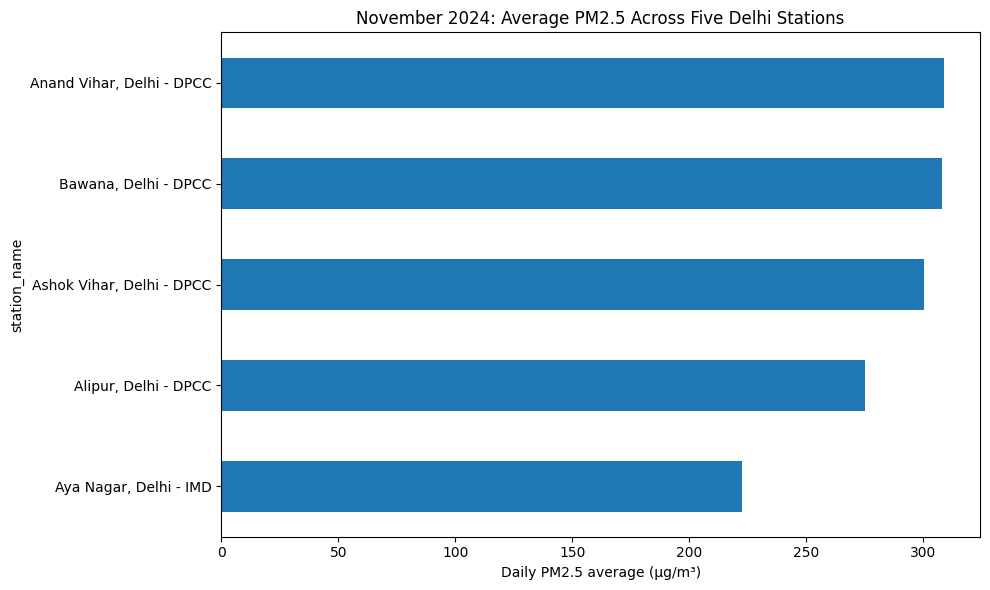

In [14]:
# Compare monthly PM2.5 averages by station
station_summary = (
    comparison_df.groupby("station_name")
    .agg(
        monthly_average=("mean", "mean"),
        highest_daily_average=("mean", "max"),
        lowest_daily_average=("mean", "min"),
        days_recorded=("mean", "count")
    )
    .round(2)
    .sort_values("monthly_average", ascending=False)
)

display(station_summary)

# Visual comparison
station_summary["monthly_average"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="November 2024: Average PM2.5 Across Five Delhi Stations",
    xlabel="Daily PM2.5 average (µg/m³)"
)

import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()

In [15]:
# Check daily coverage and missing values per station
coverage = (
    comparison_df.groupby("station_name")
    .agg(
        records=("mean", "count"),
        unique_days=("period_start", "nunique"),
        missing_averages=("mean", lambda s: s.isna().sum()),
        total_hourly_observations=("n", "sum")
    )
)

display(coverage)

,records,unique_days,missing_averages,total_hourly_observations
station_name,,,,
"Alipur, Delhi - DPCC",30,30,0,718
"Anand Vihar, Delhi - DPCC",30,30,0,686
"Ashok Vihar, Delhi - DPCC",30,30,0,714
"Aya Nagar, Delhi - IMD",30,30,0,718
"Bawana, Delhi - DPCC",30,30,0,713


In [16]:
# Save the analysis outputs
comparison_df.to_csv(
    "delhi_pm25_november_2024_all_stations.csv",
    index=False
)

station_summary.to_csv(
    "delhi_pm25_november_2024_station_summary.csv"
)

print("Saved both CSV files successfully.")

Saved both CSV files successfully.


Findings: Delhi PM2.5 Analysis — November 2024

Dataset

* Source: India Air Quality Database API
* Monitoring locations: Five stations in Delhi
* Period: 1–30 November 2024
* Pollutant: PM2.5, measured in µg/m³
* Frequency: Daily aggregated measurements

Key findings

* Anand Vihar recorded the highest monthly average among the five selected stations: 308.72 µg/m³.
* Bawana followed closely, at 308.13 µg/m³.
* Aya Nagar recorded the lowest monthly average among these stations: 222.52 µg/m³.
* All five stations had 30 daily records, no missing daily averages, and no duplicate dates.
* The daily averages varied substantially during the month, including pronounced mid-month peaks.

Limitations

This analysis covers only five selected monitoring stations and one month. The findings should not be generalized to all of Delhi or India. PM2.5 concentration is not the same as the official AQI, and the comparison does not establish the causes of observed differences.